In [20]:
# IMPORTA BIBLIOTECAS
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
from scipy.optimize import linear_sum_assignment

# gerar gráficos para visualização
import seaborn as sb

In [21]:
# DEFINIR O DATAFRAME DO DATASET = IRIS
df = pd.read_csv('pokemon_gen1.csv')

In [22]:
# VISUALIZAR O DATAFRAME - MOSTRAR AS PRIMEIRAS LINHAS
df

,Numero,Nome,Tipo_1,Tipo_2,HP,Ataque,Defesa,Ataque_Especial,Defesa_Especial,Velocidade,Total,Categoria,Lendario
0,1,Bulbasaur,Grama,Veneno,45,49,49,65,65,45,318,Semente,Não
1,2,Ivysaur,Grama,Veneno,60,62,63,80,80,60,405,Semente,Não
2,3,Venusaur,Grama,Veneno,80,82,83,100,100,80,525,Semente,Não
3,4,Charmander,Fogo,NaN,39,52,43,60,50,65,309,Lagarto,Não
4,5,Charmeleon,Fogo,NaN,58,64,58,80,65,80,405,Lagarto,Não
...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,147,Dratini,Dragão,NaN,41,64,45,50,50,50,300,Dragão,Não
147,148,Dragonair,Dragão,NaN,61,84,65,70,70,70,420,Dragão,Não
148,149,Dragonite,Dragão,Voador,91,134,95,100,100,80,600,Dragão,Não
149,150,Mewtwo,Psíquico,NaN,106,110,90,154,90,130,680,Genético,Sim


In [25]:
# TRANSFORM RÓTULOS DE TEXTO PARA NÚMEROS
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y_true = label_encoder.fit_transform(df['Tipo_1'])
x_true = label_encoder.fit_transform(df['Tipo_2'])

In [26]:
# VISUALIZAR A TRANSFOMAÇÃO DE TEXTO PARA NÚMEROS DA COLUNA Species
y_true
x_true

array([ 7,  7,  7, 10, 10,  8, 10, 10, 10, 10, 10,  8,  7,  7,  7,  8,  8,
        8, 10, 10,  8,  8, 10, 10, 10, 10, 10, 10, 10, 10,  6, 10, 10,  6,
       10, 10, 10, 10, 10, 10,  8,  8,  7,  7,  7,  2,  2,  7,  7, 10, 10,
       10, 10, 10, 10, 10, 10, 10, 10, 10, 10,  3, 10, 10, 10, 10, 10, 10,
        7,  7,  7,  7,  7,  6,  6,  6, 10, 10,  5,  5,  0,  0,  8,  8,  8,
       10,  1, 10, 10, 10,  1,  7,  7,  7,  6, 10, 10, 10, 10, 10, 10,  5,
        5, 10, 10, 10, 10, 10, 10, 10,  4,  4, 10, 10, 10, 10, 10, 10, 10,
       10,  5, 10,  8,  5, 10, 10, 10, 10, 10,  8,  1, 10, 10, 10, 10, 10,
       10,  9,  9,  9,  9,  8, 10,  8,  8,  8, 10, 10,  8, 10, 10])

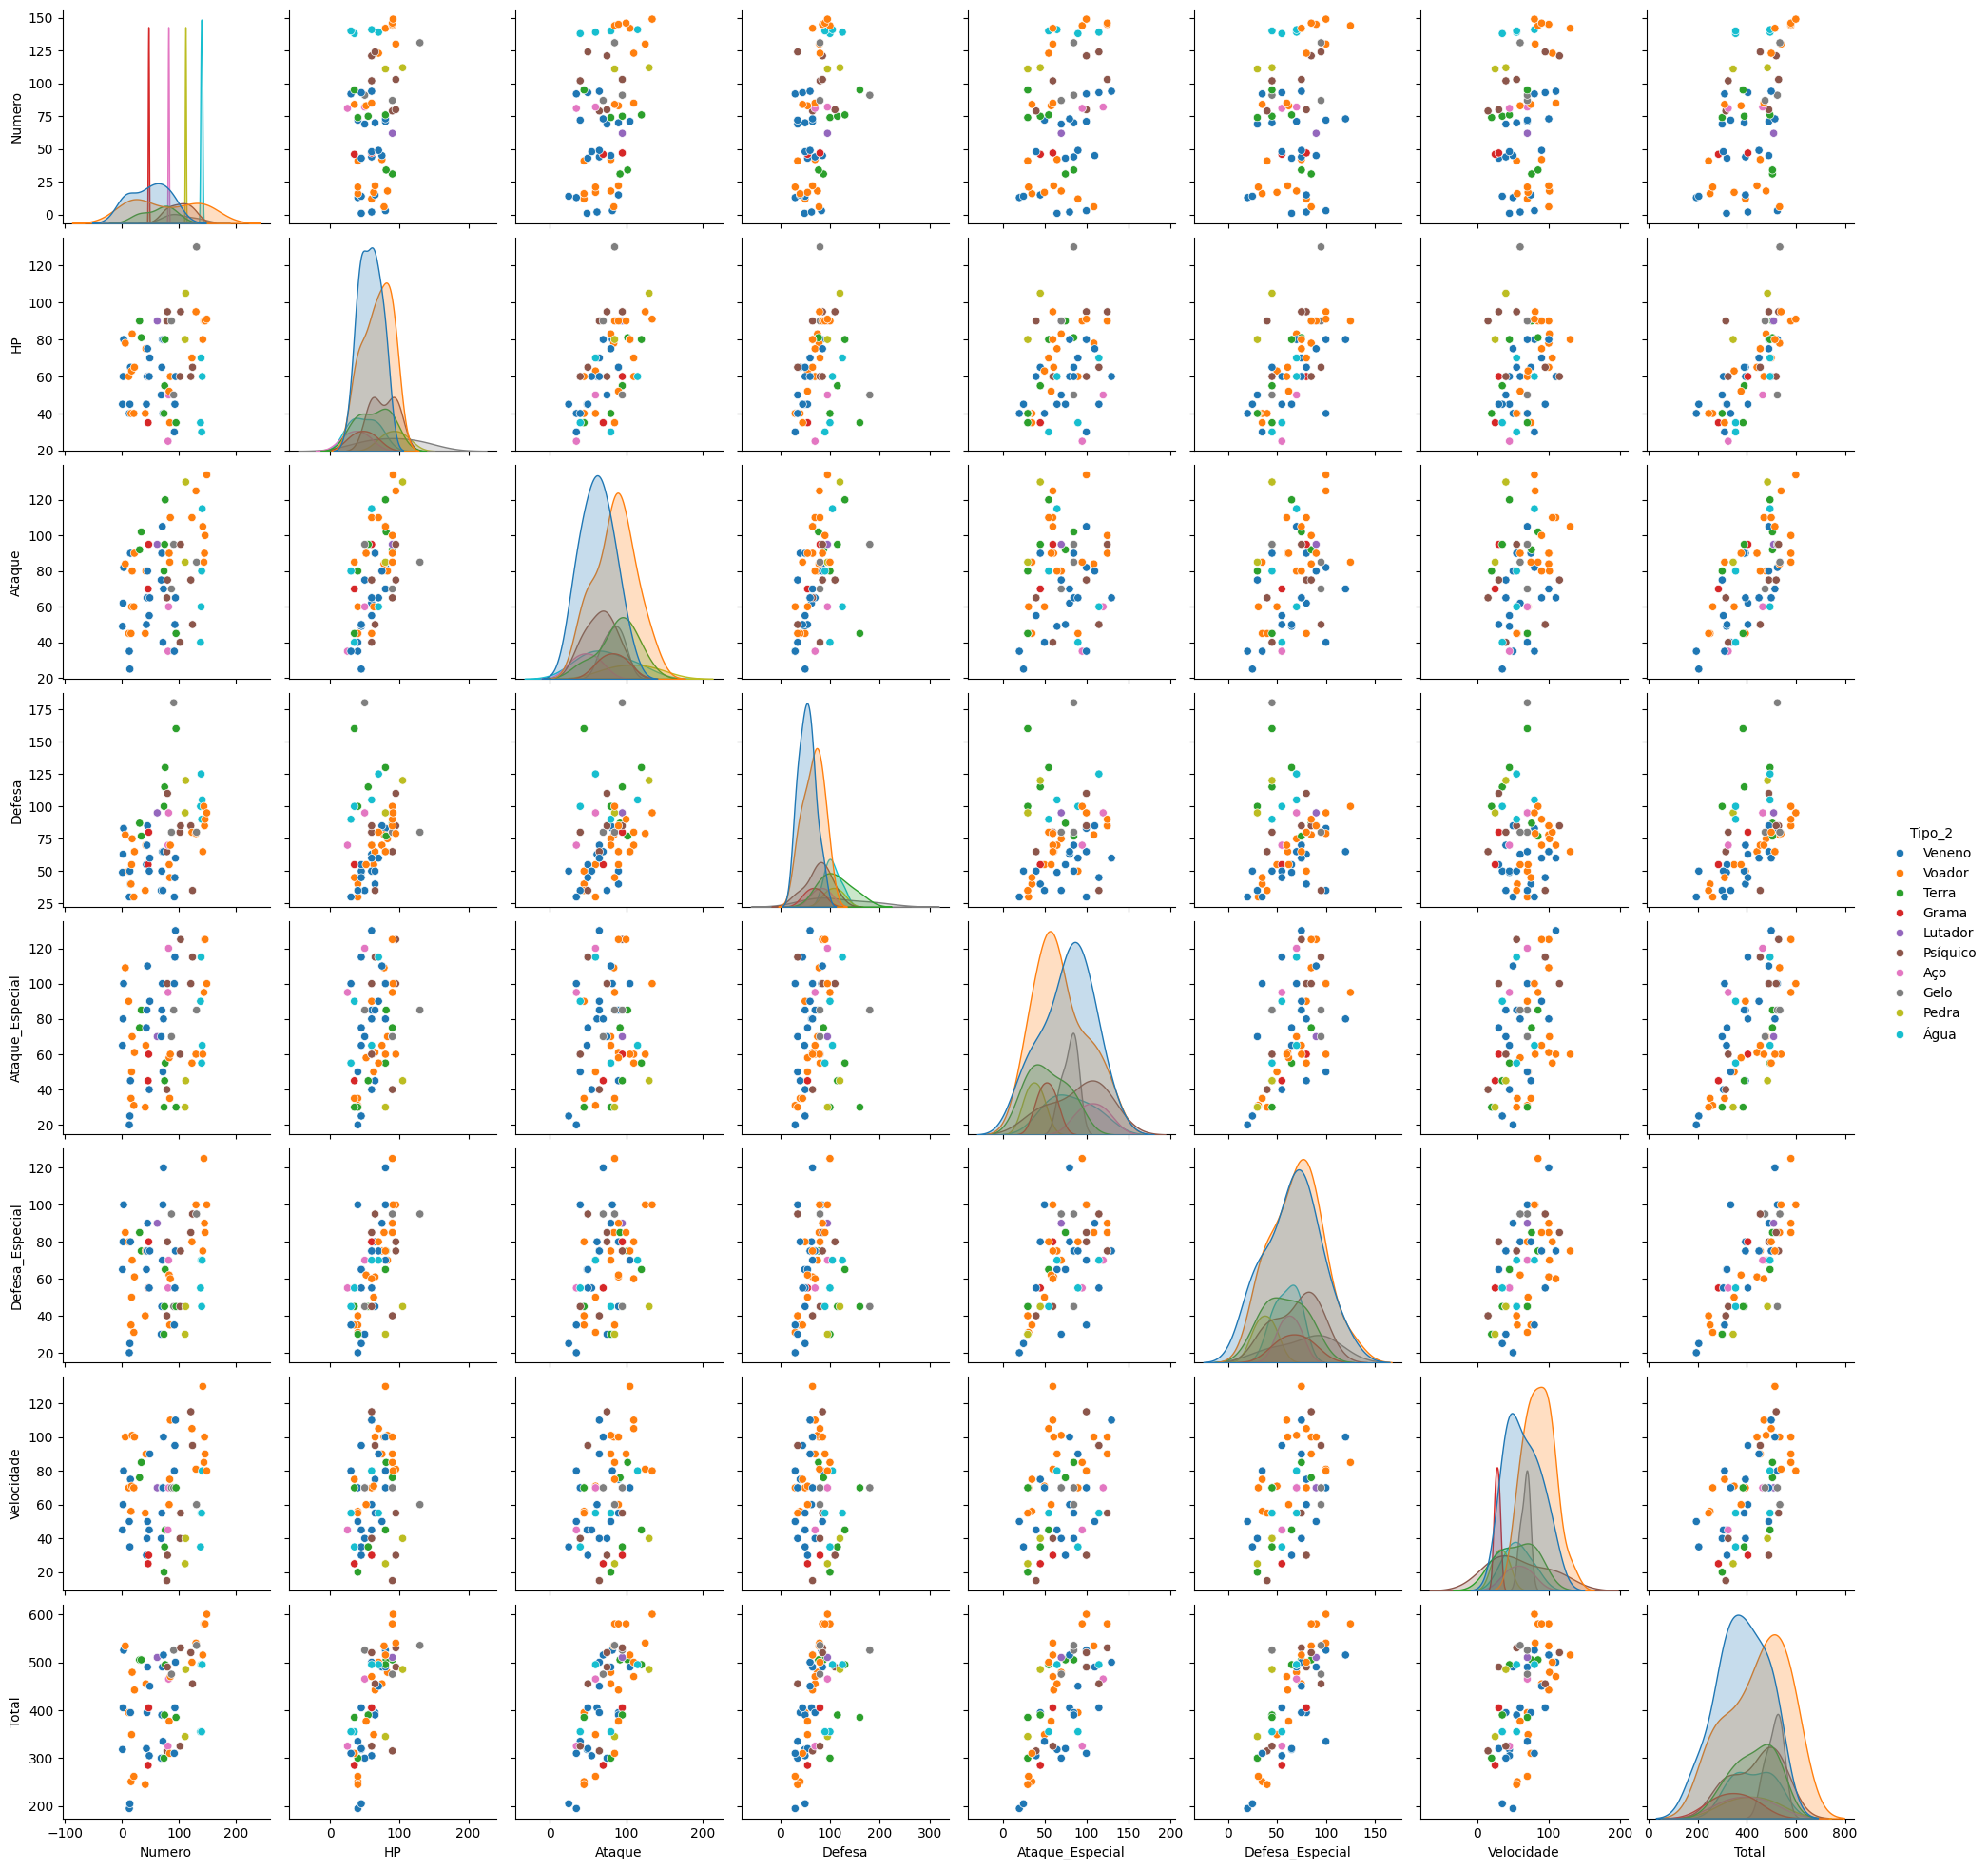

In [28]:
# VISUALIZAR O DATAFRAME ORIGINAL
sb.pairplot(df, hue="Tipo_1")

In [7]:
# COPIA DO DATAFRAME ORIGINAL REMOVENDO A COLUNA (RÓTULO LABEL) Species
X = df.select_dtypes(include=[np.number]).values
X

array([[  1,  45,  49, ...,  65,  45, 318],
       [  2,  60,  62, ...,  80,  60, 405],
       [  3,  80,  82, ..., 100,  80, 525],
       ...,
       [149,  91, 134, ..., 100,  80, 600],
       [150, 106, 110, ...,  90, 130, 680],
       [151, 100, 100, ..., 100, 100, 600]])

In [8]:
# DEFININDO O K
# CRIANDO O OBJETO KMEANS PASSANDO O NUMERO DE CLUSTERS
# TREINAMENTO INICIAL DOS DADOS SEM O RÓTULO
k = 14
kmeans = KMeans(n_clusters=k)
clusters = kmeans.fit_predict(X)
print(clusters)

[ 5 11  1  5 11  1  5 11  1  4  4 11  4  4 11  5 11  7  5  2  5  2  5  2
  5  7  5  2  5 11  7  5 11  7  0  7  5  7  0 11  5  2  0 11  7  5 11  0
  2  5  2  5  2  0  7  5  2  8  1  5 11  7  8  8 12  0 11  7  0 11  7  8
  7 13  3  6  2  7  0  7  8 12 11 13  2  0  7  0  9 13  6  8  8 12  3  0
  7 13  6  8 12 13  9 13  3  2  6  3 13  6 13  6  9  3  6 13  3 13  6  8
 12 12  6 12 12 12  6  6  4  9  9 13 13  9 12  9  3  3  6 13  6  6  9 10
 10 10 13  3 10 10 10]


In [ ]:
# RECONSTRUIU O OBJETO COM NÚMERO DE CLUSTERS E FORÇANDO SEMPRE A COMEÇAR DO MESMO PONTO
kmeans = KMeans(n_clusters=k, random_state=0)

In [9]:
# TREINAMENTO DO DATAFRAME SEM O RÓTULO SPECIES UTILIZANDO KMEANS
kmeans.fit(X)

KMeans(n_clusters=14)

In [10]:
# EXIBIR OS ROTULOS QUE FORAM GERADOS
kmeans.labels_

array([ 0,  8,  1,  0,  8,  1,  0,  8,  1,  9,  9,  8,  9,  9,  8,  9,  0,
        1,  9,  8, 13,  8, 13,  8,  0,  1, 13,  8, 13,  0,  1, 13,  0,  1,
        0,  1,  0,  1, 13, 10,  9,  8,  0,  6,  1, 13,  6, 13,  8, 13,  8,
       13,  8,  0,  1, 13,  8,  0,  1, 13,  6,  1,  0,  2, 12, 13,  6,  1,
       13,  6,  1,  3,  1,  4,  6,  5,  6,  1,  3,  1,  3, 11,  6, 13,  5,
        3,  1,  3,  1,  4,  5,  3,  2, 12,  4,  3, 12,  4,  5,  3, 12,  3,
        1,  4, 11,  5,  5,  6,  4,  5,  4,  5, 10, 11,  5,  3, 11,  3, 11,
        3, 12, 12,  5, 12, 12, 12,  5,  5,  9,  5,  7,  3,  3, 12, 12, 12,
       11,  4, 11,  4,  5, 12,  7,  7,  7,  7,  3, 11,  7,  7,  7],
      dtype=int32)

In [11]:
# CRIANDO UMA NOVA COLUNA NO DATAFRAME ORIGINAL INSERINDO OS LABELS DO DATAFRAME X QUE FOI TREINADO
df['k_classes'] = kmeans.labels_

In [12]:
# EXIBE AS 100 PRIMEIRAS LINHAS DO DATAFRAME ORIGINAL COM A NOVA COLUNA
df.head(151)

,Numero,Nome,Tipo_1,Tipo_2,HP,Ataque,Defesa,Ataque_Especial,Defesa_Especial,Velocidade,Total,Categoria,Lendario,k_classes
0,1,Bulbasaur,Grama,Veneno,45,49,49,65,65,45,318,Semente,Não,0
1,2,Ivysaur,Grama,Veneno,60,62,63,80,80,60,405,Semente,Não,8
2,3,Venusaur,Grama,Veneno,80,82,83,100,100,80,525,Semente,Não,1
3,4,Charmander,Fogo,NaN,39,52,43,60,50,65,309,Lagarto,Não,0
4,5,Charmeleon,Fogo,NaN,58,64,58,80,65,80,405,Lagarto,Não,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,147,Dratini,Dragão,NaN,41,64,45,50,50,50,300,Dragão,Não,3
147,148,Dragonair,Dragão,NaN,61,84,65,70,70,70,420,Dragão,Não,11
148,149,Dragonite,Dragão,Voador,91,134,95,100,100,80,600,Dragão,Não,7
149,150,Mewtwo,Psíquico,NaN,106,110,90,154,90,130,680,Genético,Sim,7


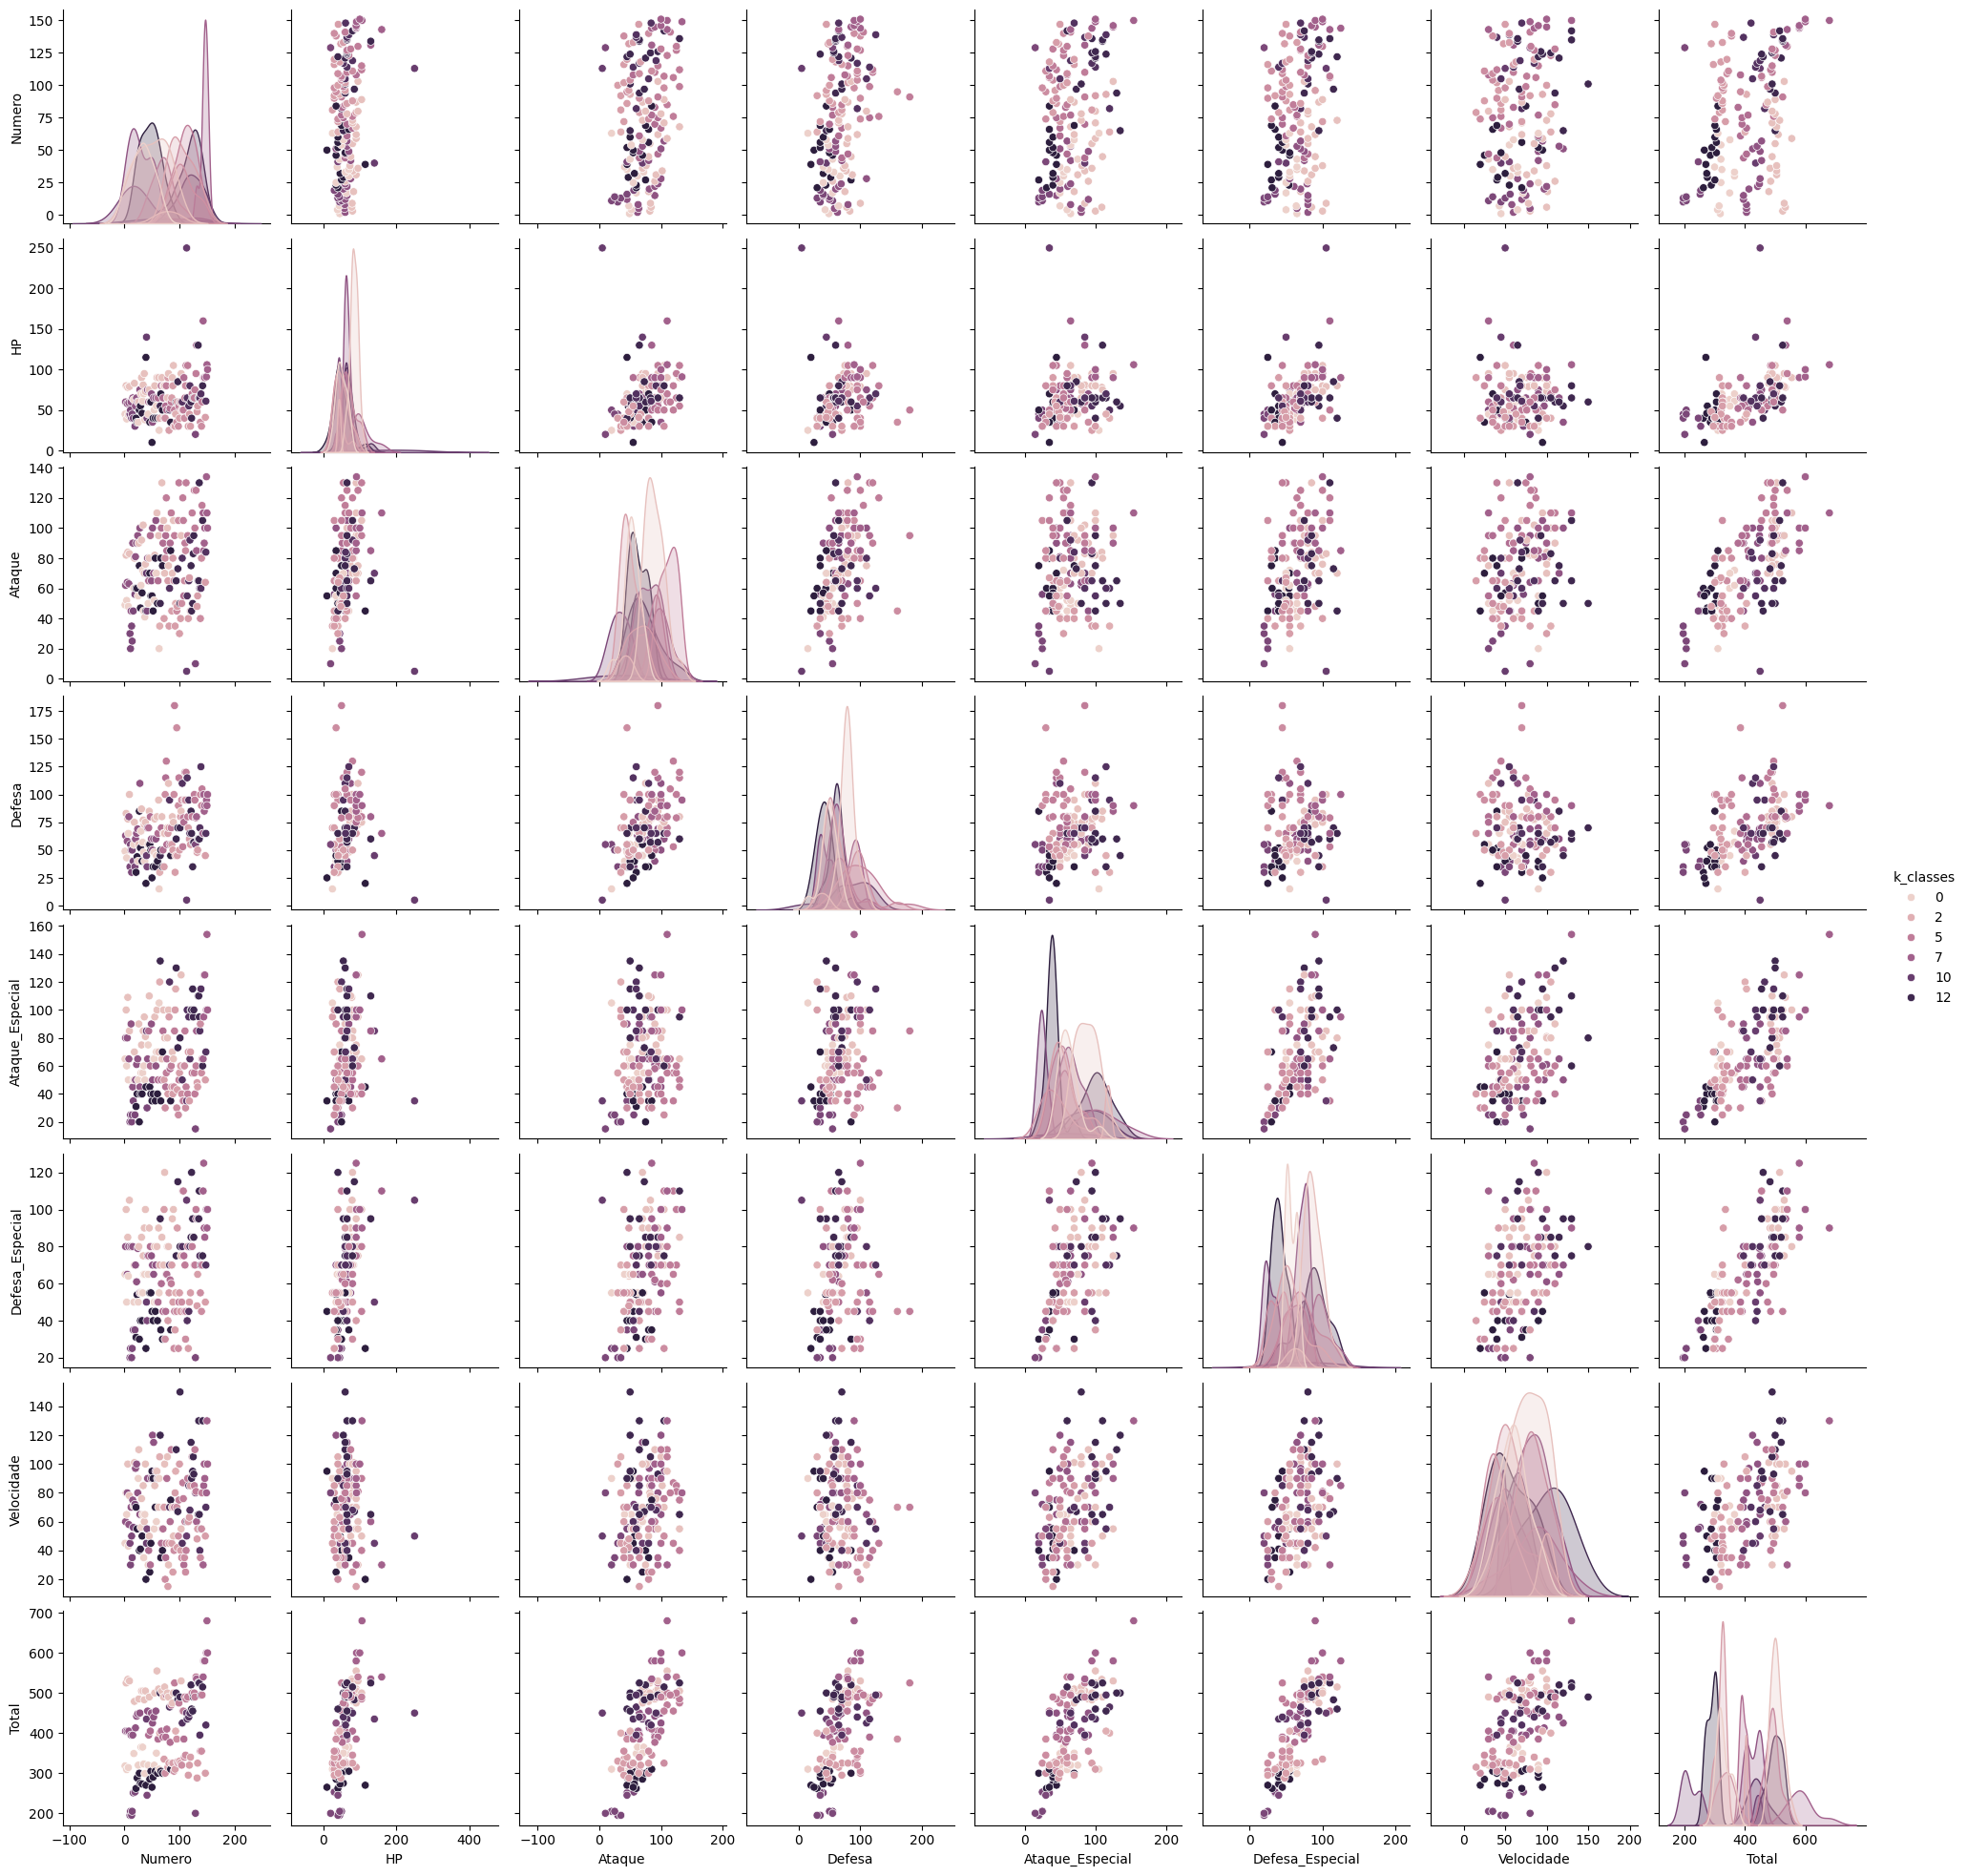

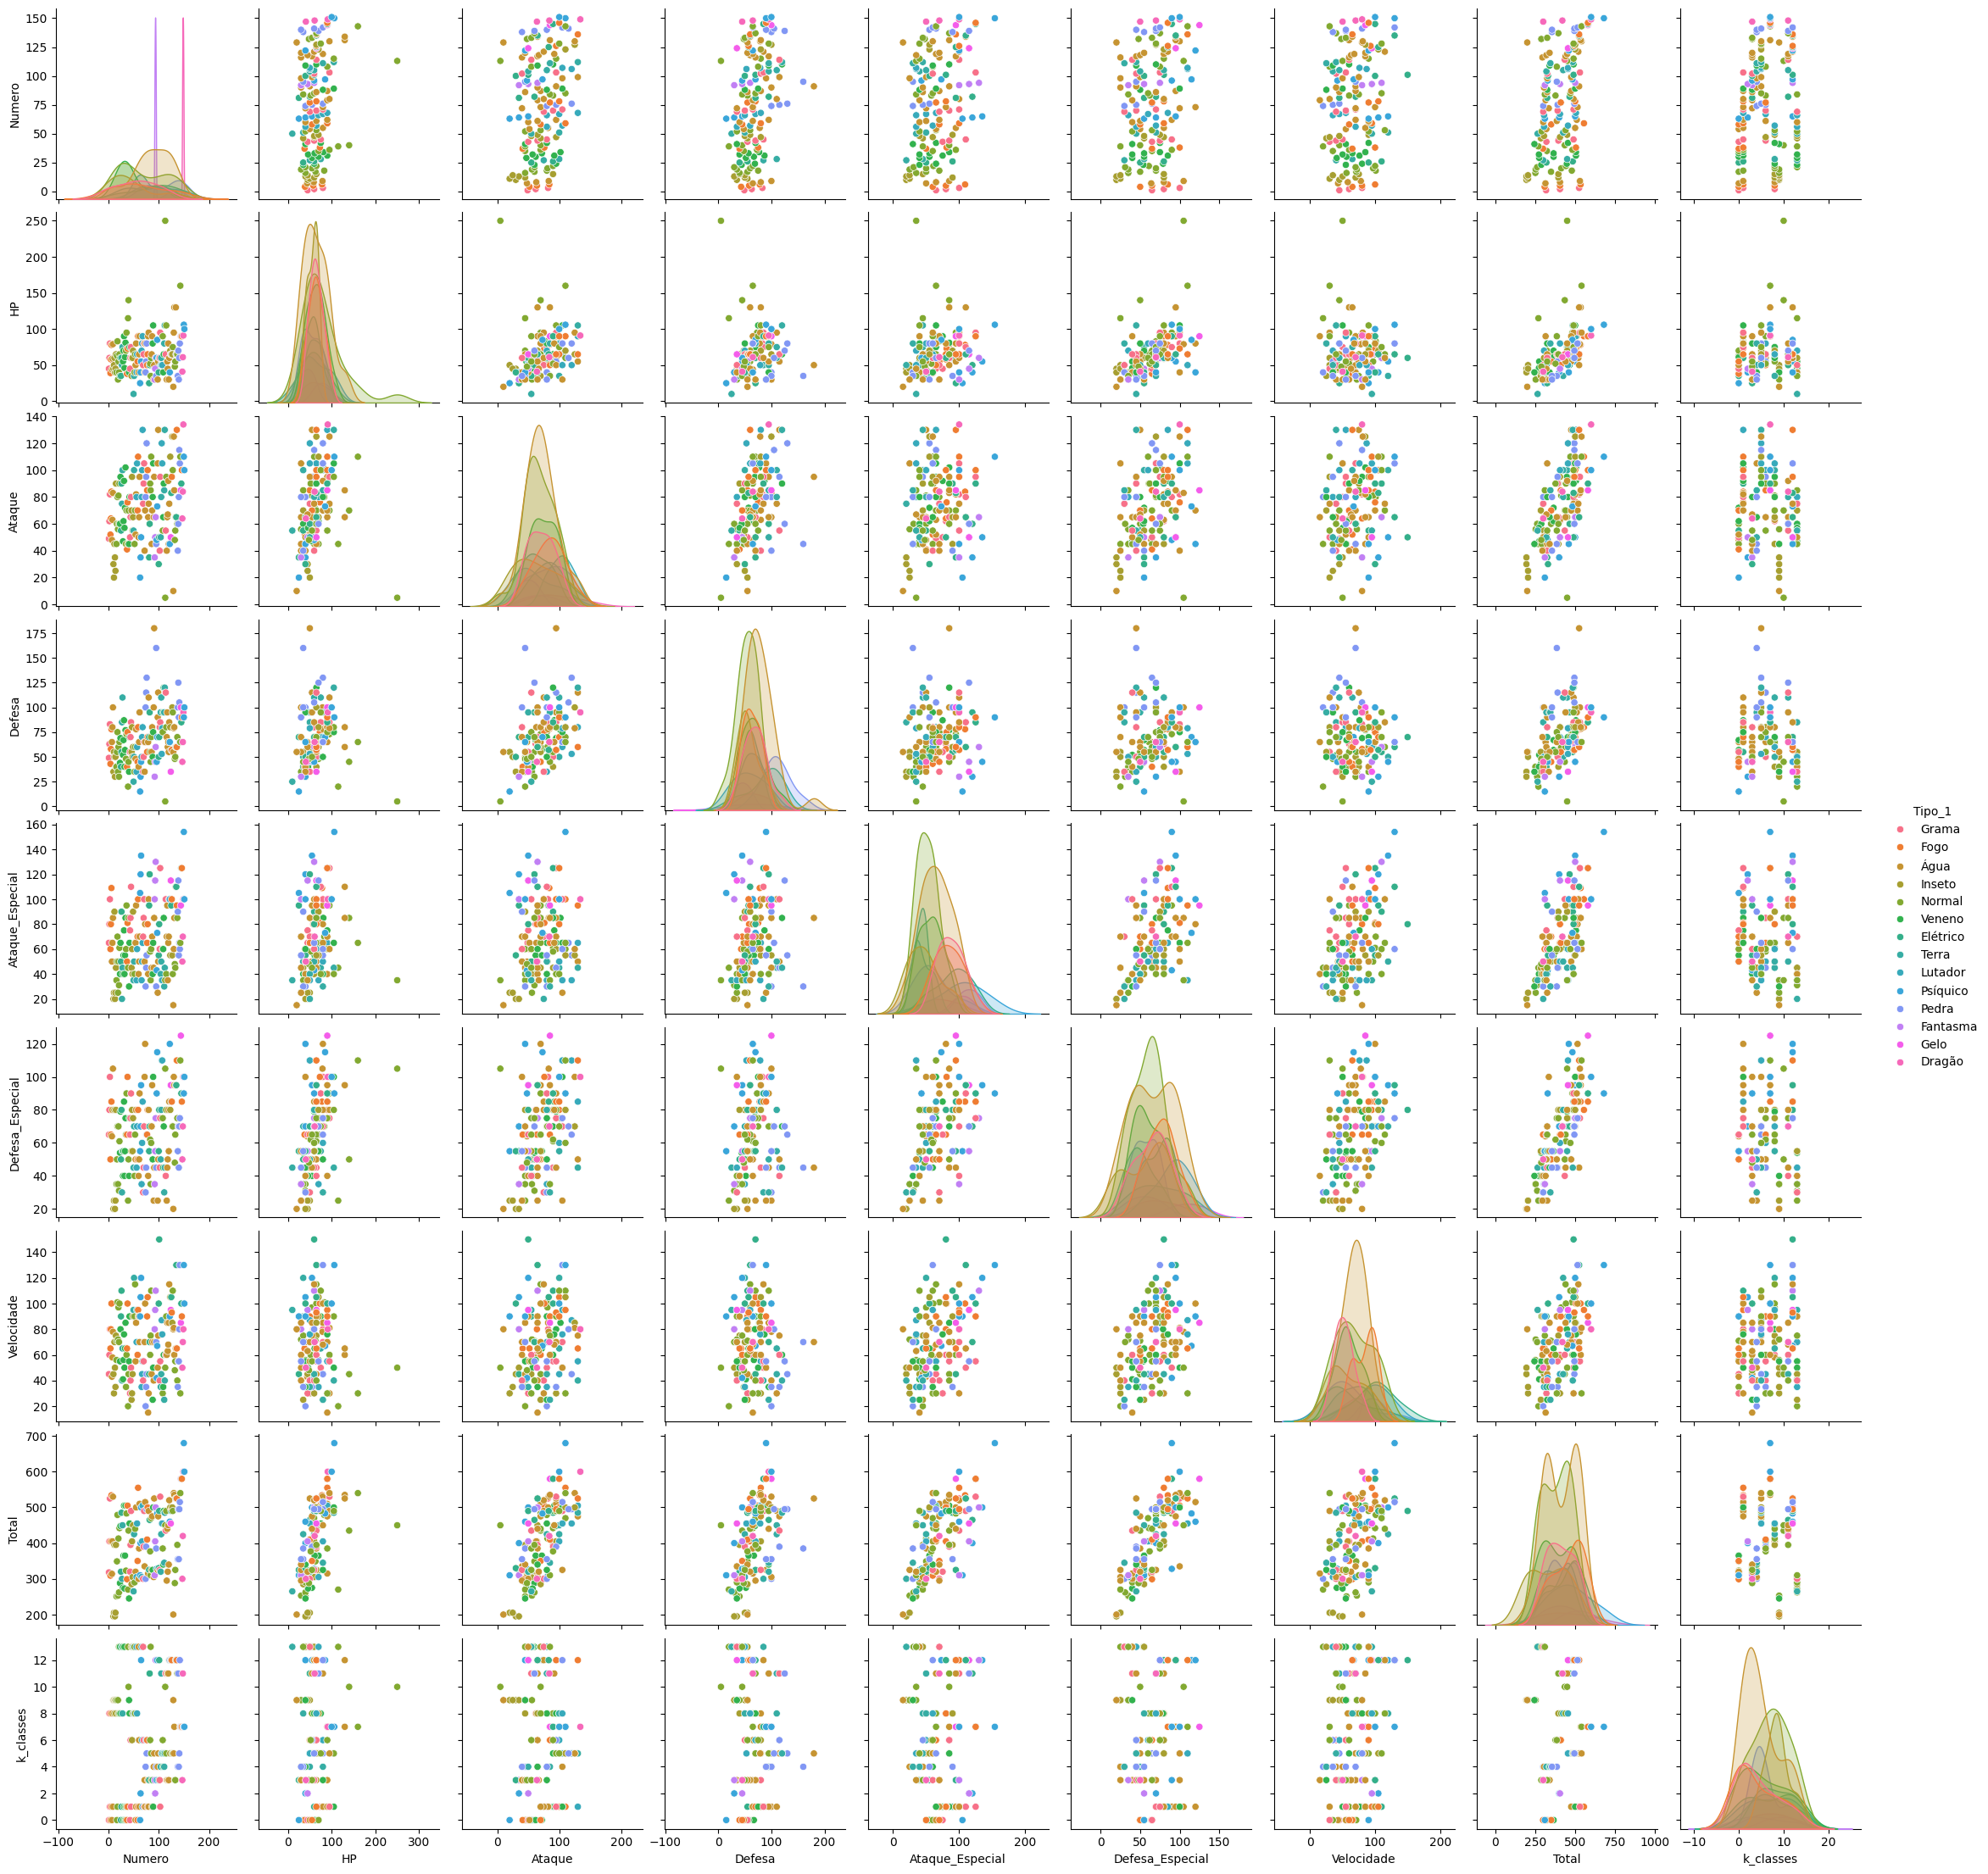

In [13]:
sb.pairplot(df, hue='k_classes')
sb.pairplot(df, hue='Tipo_1')

In [14]:
# IMPORTAÇÃO DA MATRIZ DE CONFUSÃO
# PASSA COMO ARGUMENTO y_true QUE É A TRANFORMAÇÃO DA COLUNA SPECIES DO DF ORIGINAL
# PASSA COMO ARGUMENTO clusters LISTA DE AGRUPAMENTOS DO TREINO REALIZADO COM KMEANS
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
conf_matrix = confusion_matrix(y_true, clusters)
row_ind, col_ind = linear_sum_assignment(-conf_matrix)

In [15]:
clusters_mapeados = np.zeros_like(clusters)
for i, j in zip(row_ind, col_ind):
  clusters_mapeados[clusters == i] = j

In [16]:
# REALIZAR A ACURACIA PARA VERIFICAR A QUANTIDADE DE ACERTOS EM PERCENTUAL
acuracia = accuracy_score(y_true, clusters_mapeados)
print(f"Acurácia: {acuracia * 100:.2f}%")

Acurácia: 7.95%


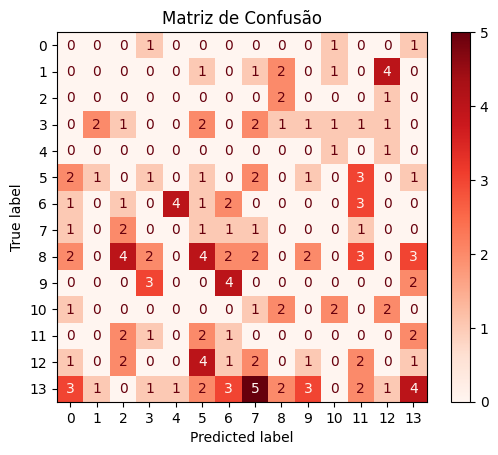

In [17]:
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot(cmap='Reds')

plt.title("Matriz de Confusão")
plt.show()

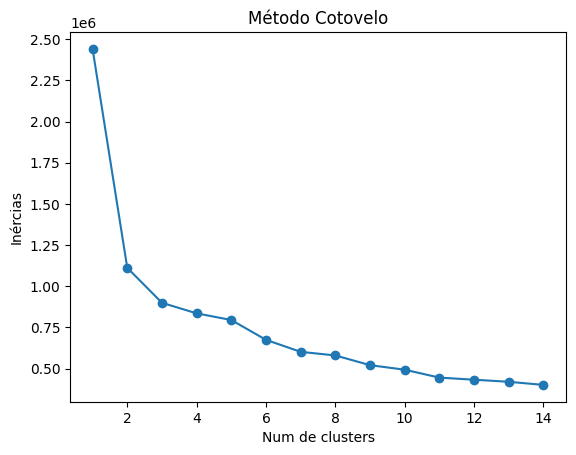

[2441411.430463576, 1111858.6732186729, 899404.2671917891, 835271.6941745684, 794857.8331893242, 674328.0025319397, 601492.9250000002, 579561.3645297085, 520554.2132730814, 492994.3841602726, 444941.8315286939, 432198.21563552954, 419566.9014438434, 400574.862049904]


In [18]:
#  ENCONTRAR O MELHOR K, O MELHOR AGRUPAMENTO
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inercias = []

for k in range(1, 15):
  kmeans = KMeans(n_clusters=k, random_state=0)
  kmeans.fit(X)
  inercias.append(kmeans.inertia_)

plt.plot(range(1, 15), inercias, marker='o')
plt.xlabel('Num de clusters')
plt.ylabel('Inércias')
plt.title('Método Cotovelo')
plt.show()
print(inercias)

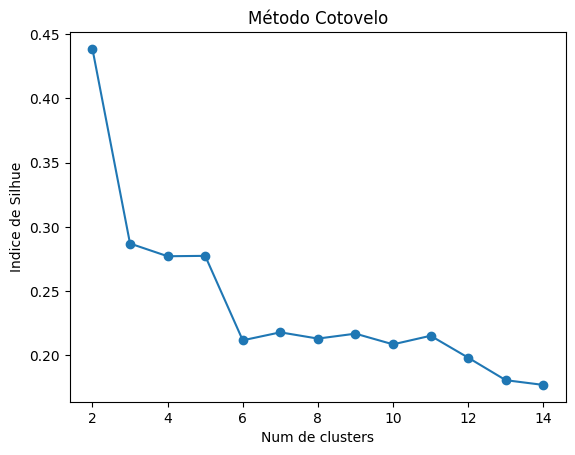

[np.float64(0.4385626869237255), np.float64(0.28712399332132393), np.float64(0.27723146637988005), np.float64(0.2775294619688753), np.float64(0.21180661360760997), np.float64(0.21801950899858794), np.float64(0.21314744036598524), np.float64(0.21698778728114046), np.float64(0.20866907659835918), np.float64(0.21535361028403244), np.float64(0.19827633040560616), np.float64(0.18077723700263298), np.float64(0.177092285013171)]


In [19]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 15):
  kmeans = KMeans(n_clusters=k, random_state=0)
  labels = kmeans.fit_predict(X)
  score = silhouette_score(X, labels)
  silhouette_scores.append(score)

plt.plot(range(2, 15), silhouette_scores, marker='o')
plt.xlabel('Num de clusters')
plt.ylabel('Indice de Silhue')
plt.title('Método Cotovelo')
plt.show()
print(silhouette_scores)
